In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('image.jpeg')

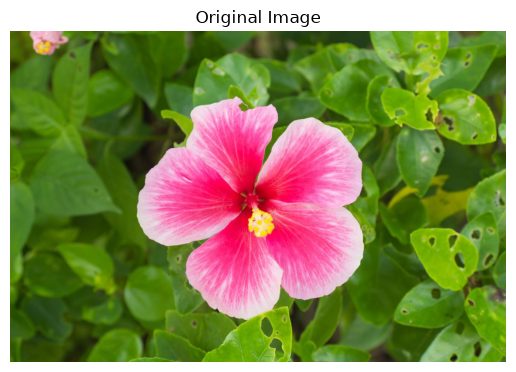

In [3]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('off')
plt.show()

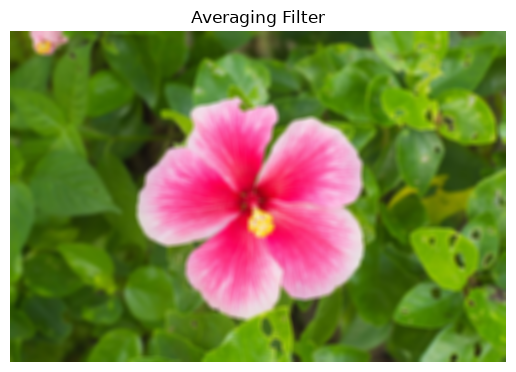

In [11]:
avg = cv2.blur(img, (15, 15))

plt.imshow(cv2.cvtColor(avg, cv2.COLOR_BGR2RGB))
plt.title('Averaging Filter')
plt.axis('off')
plt.show()

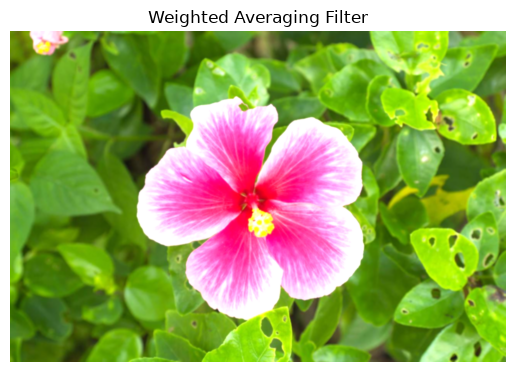

In [18]:
kernel = np.array([[1, 1, 1, 1, 1],
                   [1, 2, 2, 2, 1],
                   [1, 2, 8, 2, 1],
                   [1, 2, 2, 2, 1],
                   [1, 1, 1, 1, 1]], dtype=np.float32) / 30

weighted = cv2.filter2D(img, -1, kernel)

plt.imshow(cv2.cvtColor(weighted, cv2.COLOR_BGR2RGB))
plt.title('Weighted Averaging Filter')
plt.axis('off')
plt.show()

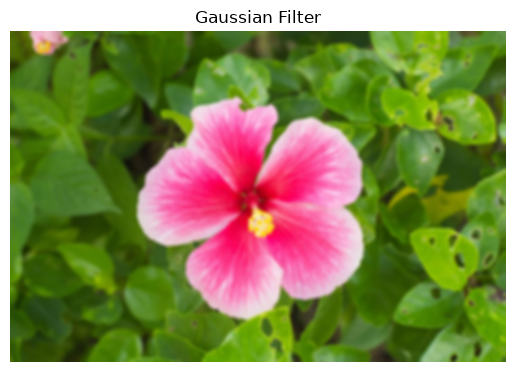

In [19]:
gaussian = cv2.GaussianBlur(img, (15, 15), 5)

plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.title('Gaussian Filter')
plt.axis('off')
plt.show()

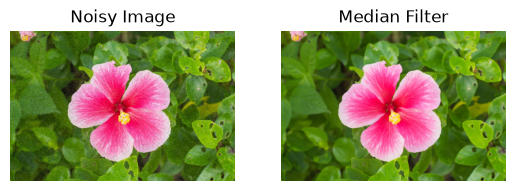

In [20]:
noisy = img.copy()

noise = np.random.randint(0, 100, img.shape[:2])
noisy[noise < 3] = 0
noisy[noise > 97] = 255

median = cv2.medianBlur(noisy, 5)

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title('Noisy Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
plt.title('Median Filter')
plt.axis('off')

plt.show()

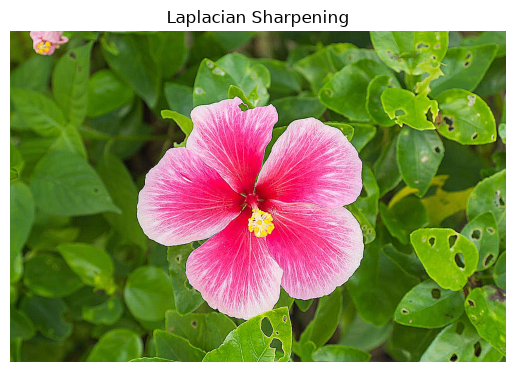

In [21]:
lap_kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])

sharp = cv2.filter2D(img, -1, lap_kernel)

plt.imshow(cv2.cvtColor(sharp, cv2.COLOR_BGR2RGB))
plt.title('Laplacian Sharpening')
plt.axis('off')
plt.show()

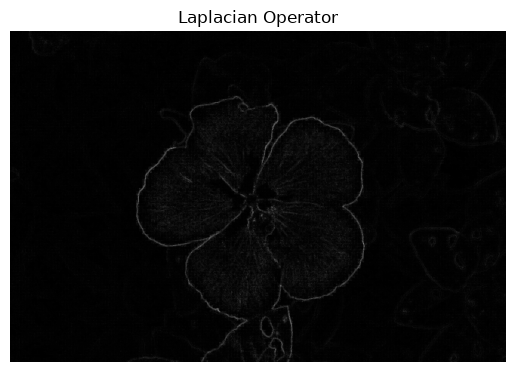

In [22]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

lap = cv2.Laplacian(gray, cv2.CV_64F)
lap = cv2.convertScaleAbs(lap)

lap = cv2.normalize(lap, None, 0, 255, cv2.NORM_MINMAX)

plt.imshow(lap, cmap='gray')
plt.title('Laplacian Operator')
plt.axis('off')
plt.show()

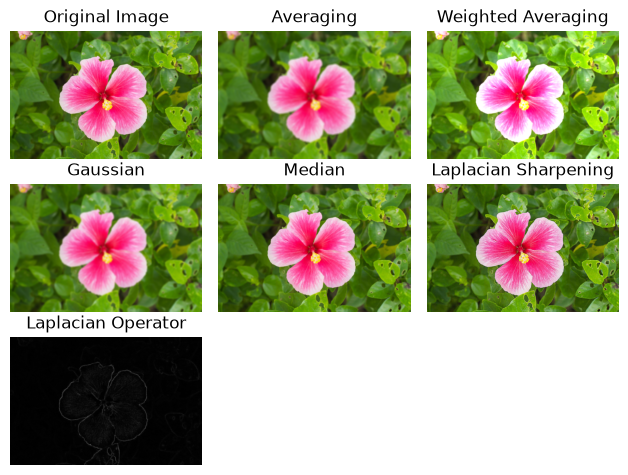

In [23]:
images = [img_rgb,
          cv2.cvtColor(avg, cv2.COLOR_BGR2RGB),
          cv2.cvtColor(weighted, cv2.COLOR_BGR2RGB),
          cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB),
          cv2.cvtColor(median, cv2.COLOR_BGR2RGB),
          cv2.cvtColor(sharp, cv2.COLOR_BGR2RGB),
          lap]

titles = ['Original Image', 'Averaging',
          'Weighted Averaging', 'Gaussian',
          'Median', 'Laplacian Sharpening',
          'Laplacian Operator']

for i in range(7):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i], cmap='gray' if i == 6 else None)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()